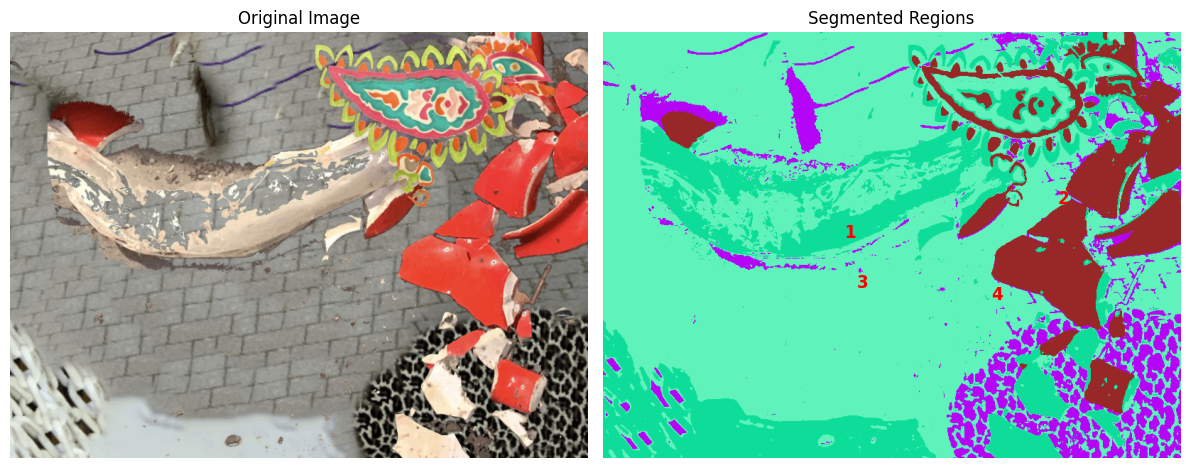

In [7]:
from typing import Any, Tuple
import numpy as np
from skimage import io, color, measure
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


class ColorSegmenter:
    """
    A class that performs color-based segmentation using K-Means clustering.

    This class:
    - Converts the input image (RGB) to the Lab color space.
    - Uses K-Means clustering to segment the image into K clusters.
    - Produces a labeled segmentation map, where each pixel is assigned to a cluster.
    """

    def __init__(self, image: np.ndarray, n_clusters: int = 3) -> None:
        """
        Initialize the ColorSegmenter with an image and the desired number of clusters.

        Args:
            image (np.ndarray): The input image as a (H, W, C) array, typically RGB.
            n_clusters (int): The number of clusters (segments) to form.
        """
        self.image = image
        self.n_clusters = n_clusters

    def segment_image(self) -> np.ndarray:
        """
        Segment the image into regions based on color clustering in Lab space.

        Steps:
        - Convert image to Lab color space.
        - Flatten image pixels into a two-dimensional array (num_pixels, 3).
        - Apply K-Means clustering to group similar colors.
        - Reshape the cluster labels to the original image dimensions.

        Returns:
            np.ndarray: A 2D integer array with the same height and width as the
                original image, where each pixel's value is the cluster label.
        """
        # Convert to Lab color space for better perceptual segmentation
        lab_image: np.ndarray = color.rgb2lab(self.image)

        # Flatten the image
        H, W, C = lab_image.shape
        lab_flat: np.ndarray = lab_image.reshape(-1, C)

        # Apply K-Means clustering
        kmeans: KMeans = KMeans(n_clusters=self.n_clusters, random_state=42)
        labels: np.ndarray = kmeans.fit_predict(lab_flat)

        # Reshape labels to the original image shape
        segmented_labels: np.ndarray = labels.reshape(H, W)
        return segmented_labels


class ImageVisualizer:
    """
    A class that provides methods to visualize the original image
    and the segmentation results (colored and labeled).
    """

    def __init__(self, original: np.ndarray, labeled: np.ndarray) -> None:
        """
        Initialize the ImageVisualizer with the original image and the labeled segmentation.

        Args:
            original (np.ndarray): The original RGB image as (H, W, 3) array.
            labeled (np.ndarray): The labeled segmentation as a (H, W) array,
                where each pixel is assigned a cluster index.
        """
        self.original = original
        self.labeled = labeled

    def visualize(self) -> None:
        """
        Display the original image and the segmentation results side-by-side.

        The segmentation results are displayed using a color map, and each
        cluster label is also overlaid at the centroid of that cluster region.
        """
        # Convert the integer labels to a color image for visualization
        # We'll just use a random colormap for different clusters
        # You could also map each cluster to a specific color.
        colored_labels = self._labels_to_color_image()

        fig, axes = plt.subplots(1, 2, figsize=(12, 6))

        # Show original image
        axes[0].imshow(self.original)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        # Show labeled segmentation image
        axes[1].imshow(colored_labels)
        axes[1].set_title("Segmented Regions")
        axes[1].axis('off')

        # Overlay label text by computing centroids of each segment
        props = measure.regionprops(self._to_labeled_mask())
        for prop in props:
            y, x = prop.centroid
            axes[1].text(x, y, str(prop.label), color='red', fontsize=12,
                         fontweight='bold', ha='center', va='center')

        plt.tight_layout()
        plt.show()

    def _labels_to_color_image(self) -> np.ndarray:
        """
        Convert a labeled image into a color image.

        Each unique label is assigned a random color.

        Returns:
            np.ndarray: An RGB image representing the segmented labels.
        """
        labels_unique = np.unique(self.labeled)
        # Generate random colors for each label
        np.random.seed(42)  # For reproducibility
        colors = {label: np.random.rand(3,) for label in labels_unique}

        H, W = self.labeled.shape
        color_img = np.zeros((H, W, 3), dtype=float)
        for h in range(H):
            for w in range(W):
                color_img[h, w] = colors[self.labeled[h, w]]

        return color_img

    def _to_labeled_mask(self) -> np.ndarray:
        """
        Convert cluster labels into a mask suitable for regionprops analysis.

        We increment labels by 1 to ensure background (0) is considered as a region if needed.
        If we prefer, we could treat one of the clusters as background, but here we assume
        all clusters are foreground segments.

        Returns:
            np.ndarray: A labeled mask where regions are labeled with integers > 0.
        """
        # Ensure labels start from 1 instead of 0 for regionprops convenience.
        labeled_mask = self.labeled.copy() + 1
        return labeled_mask


def load_image(filepath: str) -> np.ndarray:
    """
    Load an image from the specified file path as RGB.

    Args:
        filepath (str): The path to the image file.

    Returns:
        np.ndarray: An (H, W, 3) NumPy array representing the loaded RGB image.
    """
    # skimage.io.imread loads images as RGB if possible.
    image: np.ndarray = io.imread(filepath)
    # Ensure it's in RGB (if needed)
    if image.ndim == 2:
        # Grayscale to RGB
        image = np.stack([image, image, image], axis=-1)
    elif image.shape[-1] == 4:
        # If RGBA, discard alpha channel
        image = image[..., :3]
    return image


def main() -> None:
    """
    Main function demonstrating:
    - Loading a color (RGB) image.
    - Segmenting it using K-Means clustering in Lab color space.
    - Visualizing the original and segmented images side-by-side with labels.
    """
    # Example file path: "path_to_your_image.jpg"
    example_filepath: str = "image.png"

    # Load the image
    input_image: np.ndarray = load_image(example_filepath)

    # Segment the image into, for example, 4 clusters
    segmenter: ColorSegmenter = ColorSegmenter(input_image, n_clusters=4)
    labeled_segments: np.ndarray = segmenter.segment_image()

    # Visualize results
    visualizer: ImageVisualizer = ImageVisualizer(original=input_image, labeled=labeled_segments)
    visualizer.visualize()


if __name__ == "__main__":
    main()

[[  1   1   1 ...  12  12  12]
 [  1   1   1 ...  12  12  12]
 [  1   1   1 ...  12  12  12]
 ...
 [285 285 285 ... 291 291 291]
 [285 285 285 ... 291 291 291]
 [285 285 285 ... 291 291 291]]


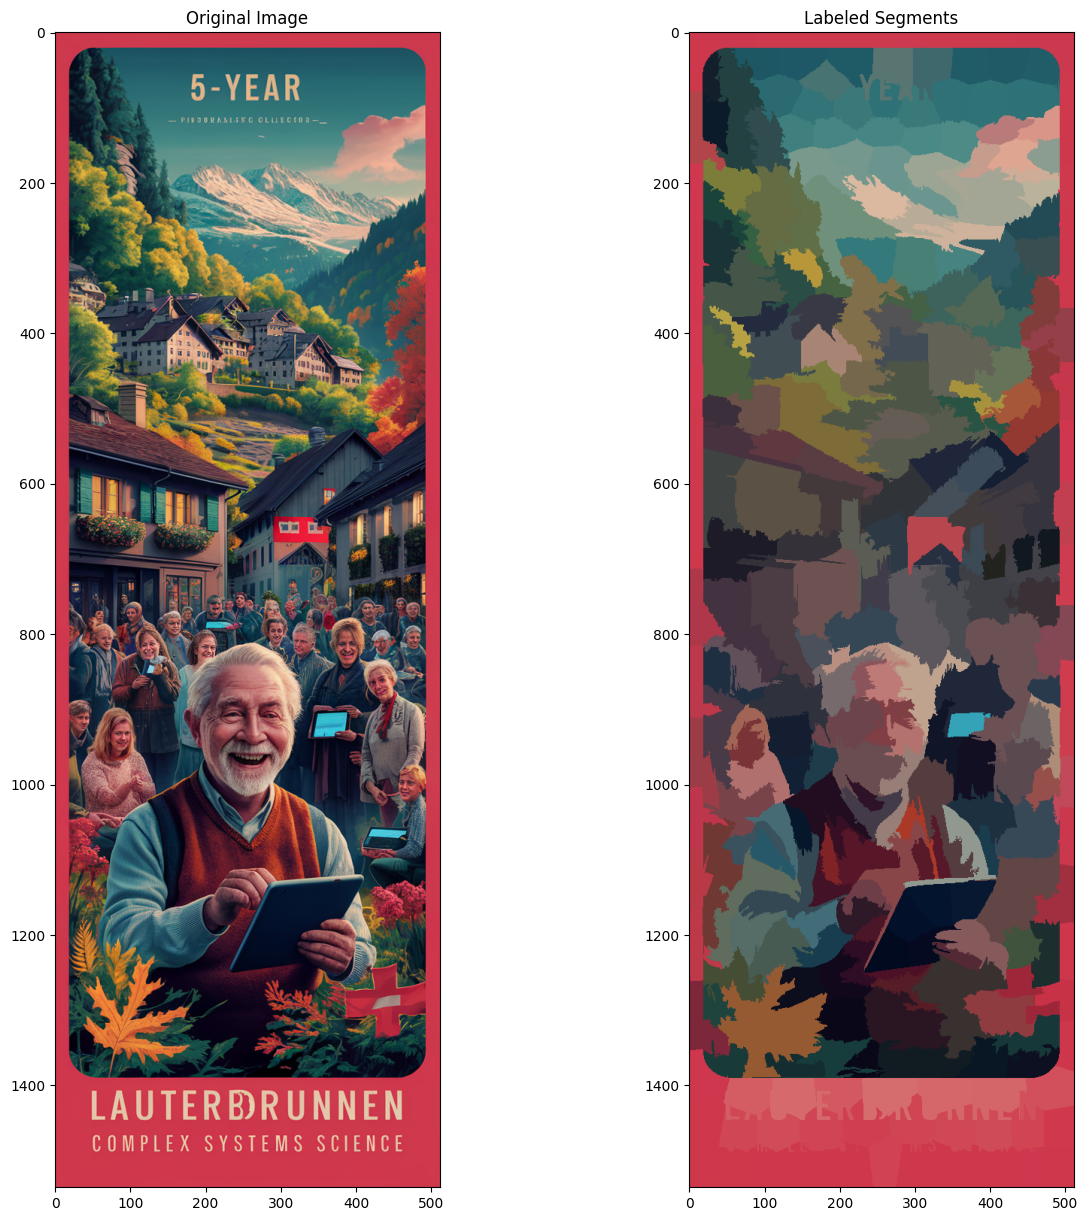

In [6]:
import matplotlib.pyplot as plt
from skimage.segmentation import slic
from skimage.io import imread
from skimage.color import label2rgb, rgba2rgb
import numpy as np

# Setting the plot size
plt.figure(figsize=(15, 15))

# Load your image from file
image_path = 'image-4.png'
image = imread(image_path)

# If the image has an alpha channel (4th channel), convert it to RGB
if image.shape[-1] == 4:  # Check if the image has 4 channels
    image = rgba2rgb(image)  # Convert RGBA to RGB
    image = (image * 255).astype(np.uint8)  # Scale values back to 0-255

# Apply Simple Linear Iterative Clustering (SLIC) on the image
# - 50 segments & compactness = 10
segments = slic(image, n_segments=500, compactness=10)
print(segments)
# Plotting the original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)

# Convert the segmented labels into an RGB color image
# for visualizing the labeled regions.
labeled_image = label2rgb(segments, image, kind='avg')

plt.subplot(1, 2, 2)
plt.title("Labeled Segments")
plt.imshow(labeled_image)

plt.show()